# ingestion_book

**Knowledge & Search Platform — ingestion demo (illustrative, made-up data)**

This notebook walks through what happens when an author uploads documents:

1. **Phase 0 (black box):** the ontology already exists. SMEs and Legal approved it.
2. **Upload document 1** (`RX-EDU-SCRIPT v3.2`): the AI splits it into knowledge units and tags each unit against the ontology. The author reviews the tags.
3. **Upload document 2** (`PHARM-OUTREACH-SCRIPT v1.7`): same extraction and tagging, then every unit is compared with what is already in the knowledge store (Chroma) and sorted into duplicate, variant, conflict, stale or new.
4. **Routing:** each finding goes to the right queue. Legal wording is never resolved by AI.

**Files needed in this folder:** `RX-EDU-SCRIPT_v3.2.md`, `PHARM-OUTREACH-SCRIPT_v1.7.md`, `knowledge_ontology_v1.json`

**Optional:** set `ANTHROPIC_API_KEY` to let Claude do the tagging and the conflict judgement. Without it, the notebook uses ontology keyword rules, so it runs offline.

## Phase 0 — Ontology (done, treated as a black box)

The unit, not the document, is what gets tagged, approved, versioned and served. Two links are never set by AI: who approved a unit (Approval Record), and which roles can read a knowledge base (Role).

The graph is drawn by the next cell.

| Class | Meaning |
|---|---|
| Knowledge Unit | Smallest piece of knowledge that is authored, approved, versioned and served on its own |
| Unit Type | `verbatim_legal`, `script_step`, `benefit_fact`, `policy_rule`, `procedure`, `definition`. Verbatim units are shown word for word, never generated |
| Compliance Class | `legal`, `clinical`, `regulatory_cms`, `operational`. Decides which approval gate applies |
| Topic | Two-level subject, e.g. `pharmacy.mail_order` |
| Lexicon Term | Humana-speak, acronyms and misspellings mapped to topics |
| Source Document | Where the unit came from; stays the source of record |
| Approval Record | Who approved which version, when (human only) |
| Lifecycle Status | draft → in review → approved → published → stale → retired |
| Knowledge Base | Governed collection; the access-control boundary |
| Role | Who may read which knowledge base (granted by a human, never inferred) |
| Channel | Advocate desktop, voice bot, member chat, web, outbound |
| Line of Business · Plan Year · Jurisdiction | Where and when a unit applies |
| Unanswered Question | A search with no approved answer; feeds the author's gap queue |

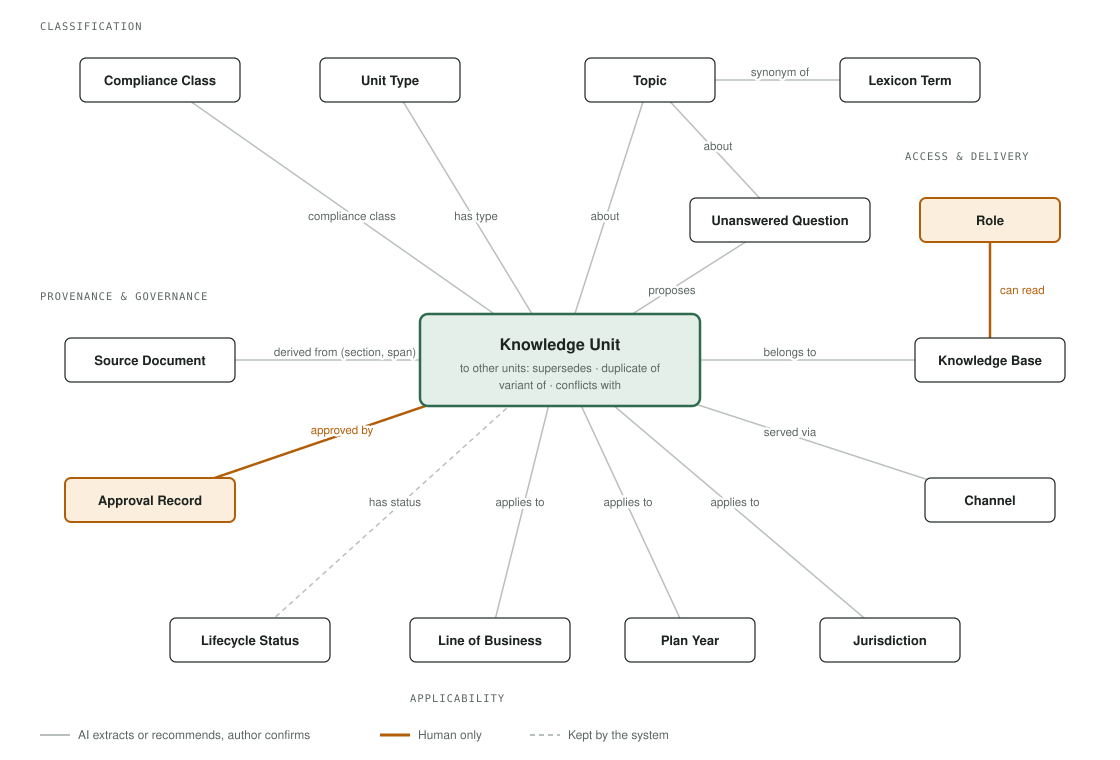

In [1]:
#@title Ontology graph { display-mode: "form" }
from IPython.display import SVG, display
ONTOLOGY_SVG = r'''<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 1120 760" width="1120" height="760" font-family="Helvetica, Arial, sans-serif"><rect width="1120" height="760" fill="#ffffff"/><text x="40" y="30" font-size="10.5" letter-spacing="1" fill="#5c6661" font-family="monospace">CLASSIFICATION</text><text x="40" y="300" font-size="10.5" letter-spacing="1" fill="#5c6661" font-family="monospace">PROVENANCE &amp; GOVERNANCE</text><text x="905" y="160" font-size="10.5" letter-spacing="1" fill="#5c6661" font-family="monospace">ACCESS &amp; DELIVERY</text><text x="410" y="702" font-size="10.5" letter-spacing="1" fill="#5c6661" font-family="monospace">APPLICABILITY</text><line x1="560" y1="360" x2="160" y2="80" stroke="#b9c0bb" stroke-width="1.5"/><line x1="560" y1="360" x2="390" y2="80" stroke="#b9c0bb" stroke-width="1.5"/><line x1="560" y1="360" x2="650" y2="80" stroke="#b9c0bb" stroke-width="1.5"/><line x1="650" y1="80" x2="910" y2="80" stroke="#b9c0bb" stroke-width="1.5"/><line x1="780" y1="220" x2="650" y2="80" stroke="#b9c0bb" stroke-width="1.5"/><line x1="780" y1="220" x2="560" y2="360" stroke="#b9c0bb" stroke-width="1.5"/><line x1="560" y1="360" x2="150" y2="360" stroke="#b9c0bb" stroke-width="1.5"/><line x1="560" y1="360" x2="990" y2="360" stroke="#b9c0bb" stroke-width="1.5"/><line x1="560" y1="360" x2="990" y2="500" stroke="#b9c0bb" stroke-width="1.5"/><line x1="560" y1="360" x2="490" y2="640" stroke="#b9c0bb" stroke-width="1.5"/><line x1="560" y1="360" x2="690" y2="640" stroke="#b9c0bb" stroke-width="1.5"/><line x1="560" y1="360" x2="890" y2="640" stroke="#b9c0bb" stroke-width="1.5"/><line x1="560" y1="360" x2="150" y2="500" stroke="#b25e09" stroke-width="2.5"/><line x1="990" y1="220" x2="990" y2="360" stroke="#b25e09" stroke-width="2.5"/><line x1="560" y1="360" x2="250" y2="640" stroke="#b9c0bb" stroke-width="1.5" stroke-dasharray="5 4"/><text x="352" y="220" text-anchor="middle" font-size="11.5" fill="#5c6661" stroke="#ffffff" stroke-width="5" paint-order="stroke" stroke-linejoin="round">compliance class</text><text x="476" y="220" text-anchor="middle" font-size="11.5" fill="#5c6661" stroke="#ffffff" stroke-width="5" paint-order="stroke" stroke-linejoin="round">has type</text><text x="605" y="220" text-anchor="middle" font-size="11.5" fill="#5c6661" stroke="#ffffff" stroke-width="5" paint-order="stroke" stroke-linejoin="round">about</text><text x="780" y="76" text-anchor="middle" font-size="11.5" fill="#5c6661" stroke="#ffffff" stroke-width="5" paint-order="stroke" stroke-linejoin="round">synonym of</text><text x="718" y="150" text-anchor="middle" font-size="11.5" fill="#5c6661" stroke="#ffffff" stroke-width="5" paint-order="stroke" stroke-linejoin="round">about</text><text x="672" y="294" text-anchor="middle" font-size="11.5" fill="#5c6661" stroke="#ffffff" stroke-width="5" paint-order="stroke" stroke-linejoin="round">proposes</text><text x="345" y="356" text-anchor="middle" font-size="11.5" fill="#5c6661" stroke="#ffffff" stroke-width="5" paint-order="stroke" stroke-linejoin="round">derived from (section, span)</text><text x="342" y="434" text-anchor="middle" font-size="11.5" fill="#b25e09" stroke="#ffffff" stroke-width="5" paint-order="stroke" stroke-linejoin="round">approved by</text><text x="395" y="506" text-anchor="middle" font-size="11.5" fill="#5c6661" stroke="#ffffff" stroke-width="5" paint-order="stroke" stroke-linejoin="round">has status</text><text x="790" y="356" text-anchor="middle" font-size="11.5" fill="#5c6661" stroke="#ffffff" stroke-width="5" paint-order="stroke" stroke-linejoin="round">belongs to</text><text x="1000" y="294" text-anchor="start" font-size="11.5" fill="#b25e09" stroke="#ffffff" stroke-width="5" paint-order="stroke" stroke-linejoin="round">can read</text><text x="790" y="436" text-anchor="middle" font-size="11.5" fill="#5c6661" stroke="#ffffff" stroke-width="5" paint-order="stroke" stroke-linejoin="round">served via</text><text x="520" y="506" text-anchor="middle" font-size="11.5" fill="#5c6661" stroke="#ffffff" stroke-width="5" paint-order="stroke" stroke-linejoin="round">applies to</text><text x="628" y="506" text-anchor="middle" font-size="11.5" fill="#5c6661" stroke="#ffffff" stroke-width="5" paint-order="stroke" stroke-linejoin="round">applies to</text><text x="735" y="506" text-anchor="middle" font-size="11.5" fill="#5c6661" stroke="#ffffff" stroke-width="5" paint-order="stroke" stroke-linejoin="round">applies to</text><rect x="80.0" y="58" width="160" height="44" rx="6" fill="#ffffff" stroke="#1d2320" stroke-width="1.2"/><text x="160" y="85" text-anchor="middle" font-size="13" font-weight="600" fill="#1d2320">Compliance Class</text><rect x="320.0" y="58" width="140" height="44" rx="6" fill="#ffffff" stroke="#1d2320" stroke-width="1.2"/><text x="390" y="85" text-anchor="middle" font-size="13" font-weight="600" fill="#1d2320">Unit Type</text><rect x="585.0" y="58" width="130" height="44" rx="6" fill="#ffffff" stroke="#1d2320" stroke-width="1.2"/><text x="650" y="85" text-anchor="middle" font-size="13" font-weight="600" fill="#1d2320">Topic</text><rect x="840.0" y="58" width="140" height="44" rx="6" fill="#ffffff" stroke="#1d2320" stroke-width="1.2"/><text x="910" y="85" text-anchor="middle" font-size="13" font-weight="600" fill="#1d2320">Lexicon Term</text><rect x="690.0" y="198" width="180" height="44" rx="6" fill="#ffffff" stroke="#1d2320" stroke-width="1.2"/><text x="780" y="225" text-anchor="middle" font-size="13" font-weight="600" fill="#1d2320">Unanswered Question</text><rect x="920.0" y="198" width="140" height="44" rx="6" fill="#fbeedd" stroke="#b25e09" stroke-width="2"/><text x="990" y="225" text-anchor="middle" font-size="13" font-weight="600" fill="#1d2320">Role</text><rect x="65.0" y="338" width="170" height="44" rx="6" fill="#ffffff" stroke="#1d2320" stroke-width="1.2"/><text x="150" y="365" text-anchor="middle" font-size="13" font-weight="600" fill="#1d2320">Source Document</text><rect x="65.0" y="478" width="170" height="44" rx="6" fill="#fbeedd" stroke="#b25e09" stroke-width="2"/><text x="150" y="505" text-anchor="middle" font-size="13" font-weight="600" fill="#1d2320">Approval Record</text><rect x="170.0" y="618" width="160" height="44" rx="6" fill="#ffffff" stroke="#1d2320" stroke-width="1.2"/><text x="250" y="645" text-anchor="middle" font-size="13" font-weight="600" fill="#1d2320">Lifecycle Status</text><rect x="915.0" y="338" width="150" height="44" rx="6" fill="#ffffff" stroke="#1d2320" stroke-width="1.2"/><text x="990" y="365" text-anchor="middle" font-size="13" font-weight="600" fill="#1d2320">Knowledge Base</text><rect x="925.0" y="478" width="130" height="44" rx="6" fill="#ffffff" stroke="#1d2320" stroke-width="1.2"/><text x="990" y="505" text-anchor="middle" font-size="13" font-weight="600" fill="#1d2320">Channel</text><rect x="410.0" y="618" width="160" height="44" rx="6" fill="#ffffff" stroke="#1d2320" stroke-width="1.2"/><text x="490" y="645" text-anchor="middle" font-size="13" font-weight="600" fill="#1d2320">Line of Business</text><rect x="625.0" y="618" width="130" height="44" rx="6" fill="#ffffff" stroke="#1d2320" stroke-width="1.2"/><text x="690" y="645" text-anchor="middle" font-size="13" font-weight="600" fill="#1d2320">Plan Year</text><rect x="820.0" y="618" width="140" height="44" rx="6" fill="#ffffff" stroke="#1d2320" stroke-width="1.2"/><text x="890" y="645" text-anchor="middle" font-size="13" font-weight="600" fill="#1d2320">Jurisdiction</text><rect x="420" y="314" width="280" height="92" rx="8" fill="#e3efe8" stroke="#2f6b4f" stroke-width="2.5"/><text x="560" y="350" text-anchor="middle" font-size="16" font-weight="700" fill="#1d2320">Knowledge Unit</text><text x="560" y="372" text-anchor="middle" font-size="11.5" fill="#5c6661">to other units: supersedes · duplicate of</text><text x="560" y="389" text-anchor="middle" font-size="11.5" fill="#5c6661">variant of · conflicts with</text><line x1="40" y1="735" x2="70" y2="735" stroke="#b9c0bb" stroke-width="2"/><text x="78" y="739" font-size="12" fill="#5c6661">AI extracts or recommends, author confirms</text><line x1="380" y1="735" x2="410" y2="735" stroke="#b25e09" stroke-width="3"/><text x="418" y="739" font-size="12" fill="#5c6661">Human only</text><line x1="530" y1="735" x2="560" y2="735" stroke="#b9c0bb" stroke-width="2" stroke-dasharray="5 4"/><text x="568" y="739" font-size="12" fill="#5c6661">Kept by the system</text></svg>'''
display(SVG(ONTOLOGY_SVG))

In [2]:
# Colab / first-run setup: installs Chroma and checks the three data files are present.
import importlib.util, os, sys, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if importlib.util.find_spec("chromadb") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "chromadb", "anthropic"], check=True)

NEEDED = ["RX-EDU-SCRIPT_v3.2.md", "PHARM-OUTREACH-SCRIPT_v1.7.md", "knowledge_ontology_v1.json"]
missing = [f for f in NEEDED if not Path(f).exists()]
if missing and IN_COLAB:
    from google.colab import files
    print("Upload these files:", ", ".join(missing))
    files.upload()
    missing = [f for f in NEEDED if not Path(f).exists()]
print("Missing files: " + ", ".join(missing) if missing else "All data files present.")

# Optional: in Colab, store your key under Secrets (key icon) as ANTHROPIC_API_KEY.
if IN_COLAB and not os.getenv("ANTHROPIC_API_KEY"):
    try:
        from google.colab import userdata
        os.environ["ANTHROPIC_API_KEY"] = userdata.get("ANTHROPIC_API_KEY")
        print("Using ANTHROPIC_API_KEY from Colab Secrets.")
    except Exception:
        print("No API key found: running offline with ontology rules.")

All data files present.


In [3]:
# Setup
import os, re, json, html, difflib, hashlib
from pathlib import Path
import numpy as np
import chromadb
from IPython.display import display, HTML

DATA_DIR = Path(".")
DOC_1 = DATA_DIR / "RX-EDU-SCRIPT_v3.2.md"
DOC_2 = DATA_DIR / "PHARM-OUTREACH-SCRIPT_v1.7.md"
ONTOLOGY = json.loads((DATA_DIR / "knowledge_ontology_v1.json").read_text())

USE_LLM = bool(os.getenv("ANTHROPIC_API_KEY"))
UPLOADER = "Maya Ortiz, Knowledge Ops author"   # who uploads (supplied at upload, not read from the doc)
LLM_MODEL = "claude-sonnet-5-5"

# Similarity needed before two units are compared at all (cosine, 0-1).
VERBATIM_MATCH = 0.55
GUIDANCE_MATCH = 0.50

print(f"Ontology: {ONTOLOGY['name']} v{ONTOLOGY['version']}")
print(f"Tagging and conflict judgement: {'Claude (' + LLM_MODEL + ')' if USE_LLM else 'ontology keyword rules (offline)'}")

Ontology: Humana Knowledge Ontology (illustrative) v1.0
Tagging and conflict judgement: ontology keyword rules (offline)


In [4]:
# 1. Split a document into knowledge units
VERBATIM_MARK = re.compile(r"^\*\*\[VERBATIM\s*[–-]\s*LEGAL\]\*\*\s*$")
SKIP_SECTIONS = {"revision history"}

def clean(s):
    s = re.sub(r"\*+", "", s)
    return re.sub(r"[ \t]+", " ", s).strip()

def parse_document(path):
    text = path.read_text()
    head = text.split("\n## ")[0]
    meta = {}
    for k, v in re.findall(r"^\|\s*([^|]+?)\s*\|\s*([^|]+?)\s*\|\s*$", head, re.M):
        if k != "Field" and not set(k) <= set("-: "):
            meta[k] = v
    meta["Title"] = re.search(r"^# (.+)$", text, re.M).group(1)
    meta["_raw"] = text
    lob = sorted(set(re.findall(r"\b(MAPD|PDP|DSNP)\b", text)))
    units = []
    for sec in re.split(r"^## ", text, flags=re.M)[1:]:
        heading, _, body = sec.partition("\n")
        num, sec_title = re.match(r"(\d+)\.\s*(.+)", heading.strip()).groups()
        if sec_title.lower() in SKIP_SECTIONS:
            continue
        lines = [l for l in body.split("\n") if l.strip() != "---"]
        verbatims, guidance, i = [], [], 0
        while i < len(lines):
            if VERBATIM_MARK.match(lines[i].strip()):
                i, block = i + 1, []
                while i < len(lines) and lines[i].strip():
                    block.append(lines[i].strip()); i += 1
                verbatims.append(clean(" ".join(block)))
            else:
                guidance.append(lines[i]); i += 1
        for k, v in enumerate(verbatims, 1):
            units.append(dict(section=f"§{num}", title=sec_title, text=v, is_verbatim=True, uid=f"{meta['Document ID']}§{num}.V{k}"))
        g = clean("\n".join(guidance))
        if g:
            units.append(dict(section=f"§{num}", title=sec_title, text=g, is_verbatim=False, uid=f"{meta['Document ID']}§{num}.G"))
    for u in units:
        u.update(doc_id=meta["Document ID"], doc_version=meta["Version"], plan_year=meta.get("Plan year", ""),
                 lob=", ".join(lob), approval_id=meta.get("Legal approval", "").split(" ")[0])
    return meta, units

# 2. Tag each unit against the ontology
TOPIC_KW = ONTOLOGY["classes"]["Topic"]["keywords"]
KB_FOR = {"pharmacy": "pharmacy", "insurance": "insurance", "member_service": "shared_member_service"}

def kw_count(kw, s):
    return len(re.findall(r"\b" + re.escape(kw), s))

def rule_tags(u, meta):
    t, b = u["title"].lower(), u["text"].lower()
    scores = {tp: sum(5 * kw_count(k, t) + kw_count(k, b) for k in kws) for tp, kws in TOPIC_KW.items()}
    topic = max(scores, key=scores.get) if max(scores.values()) else "member_service.call_handling"
    if u["is_verbatim"]:
        utype = "verbatim_legal"
    elif re.search(r"\$\d|\d+% coinsurance", u["text"]):
        utype = "benefit_fact"
    elif "coverage rules" in t:
        utype = "policy_rule"
    elif any(w in t for w in ("purpose", "escalation", "disposition", "premium", "do-not-call")):
        utype = "procedure"
    else:
        utype = "script_step"
    return dict(unit_type=utype, topic=topic)

def llm_json(prompt):
    import anthropic
    msg = anthropic.Anthropic().messages.create(model=LLM_MODEL, max_tokens=6000,
                                                messages=[{"role": "user", "content": prompt}])
    txt = msg.content[0].text
    return json.loads(re.search(r"[\[{].*[\]}]", txt, re.S).group(0))

def llm_tags(units):
    allowed = {"unit_type": list(ONTOLOGY["classes"]["UnitType"]["values"]), "topic": list(TOPIC_KW)}
    payload = [{"uid": u["uid"], "title": u["title"], "text": u["text"][:1500]} for u in units]
    prompt = (f"Tag each knowledge unit using ONLY these values: {json.dumps(allowed)}. "
              f"Return a JSON list of objects with keys uid, unit_type, topic.\n\n{json.dumps(payload)}")
    out = {r["uid"]: r for r in llm_json(prompt)}
    return out, allowed

def tag_units(units, meta):
    llm = {}
    if USE_LLM:
        try:
            llm, allowed = llm_tags(units)
        except Exception as e:
            print(f"Claude tagging failed, using rules instead: {e}")
    channel = "outbound" if "outbound" in meta.get("Audience", "").lower() else "advocate_desktop"
    for u in units:
        tags = rule_tags(u, meta)
        r = llm.get(u["uid"], {})
        if r.get("topic") in TOPIC_KW: tags["topic"] = r["topic"]
        if r.get("unit_type") in ONTOLOGY["classes"]["UnitType"]["values"]: tags["unit_type"] = r["unit_type"]
        if u["is_verbatim"]:                       # policy beats model: marked verbatim is always legal verbatim
            tags["unit_type"] = "verbatim_legal"
        ut = tags["unit_type"]
        tags["compliance_class"] = ("legal" if ut == "verbatim_legal" else
                                    "regulatory_cms" if ut in ("benefit_fact", "policy_rule") or tags["topic"] == "pharmacy.drug_payment_stages" else
                                    "operational")
        tags["kb"] = KB_FOR[tags["topic"].split(".")[0]]
        tags["channel"] = channel
        tags["approval_gate"] = ONTOLOGY["approval_policy"][tags["compliance_class"]]
        u.update(tags)
    return units

In [5]:
# 3. Knowledge store (Chroma) and display helpers

class WordingEmbedding:
    """Character 3-5-gram hashing embedding. It is sensitive to exact wording, which is what
    near-duplicate legal text needs, and needs no model download. Semantic embeddings
    belong to the search phase, not to dedup at ingestion."""
    def __init__(self, dim=4096):
        self.dim = dim
    def __call__(self, texts):
        out = []
        for doc in texts:
            v = np.zeros(self.dim)
            s = " " + re.sub(r"\s+", " ", doc.lower()) + " "
            for n in (3, 4, 5):
                for i in range(len(s) - n + 1):
                    v[int(hashlib.md5(s[i:i+n].encode()).hexdigest()[:8], 16) % self.dim] += 1
            out.append((v / (np.linalg.norm(v) or 1)).tolist())
        return out

embed = WordingEmbedding()
client = chromadb.EphemeralClient()
try:
    client.delete_collection("knowledge_units")
except Exception:
    pass
store = client.create_collection("knowledge_units", metadata={"hnsw:space": "cosine"}, embedding_function=None)

def publish(units, approver, approval_id):
    store.add(ids=[u["uid"] for u in units], embeddings=embed([u["text"] for u in units]), documents=[u["text"] for u in units],
              metadatas=[{k: u[k] for k in ("doc_id", "doc_version", "section", "title", "unit_type", "topic", "kb",
                                             "compliance_class", "plan_year", "channel", "is_verbatim")}
                         | {"status": "published", "approved_by": approver, "approval_id": approval_id} for u in units])

# --- display helpers ---
PILL = {"verbatim_legal": "#b25e09", "legal": "#b25e09", "regulatory_cms": "#7a4fa3", "operational": "#5c6661",
        "benefit_fact": "#2f6b4f", "policy_rule": "#2f6b4f", "script_step": "#3c6e91", "procedure": "#3c6e91", "definition": "#3c6e91"}
CSS = """<style>
.kt{border-collapse:collapse;font:13px/1.45 -apple-system,Segoe UI,Helvetica,Arial,sans-serif;width:100%}
.kt th{text-align:left;font-weight:600;font-size:11.5px;text-transform:uppercase;letter-spacing:.04em;color:#5c6661;border-bottom:2px solid #c9cfcb;padding:6px 8px}
.kt td{border-bottom:1px solid #e3e6e4;padding:6px 8px;vertical-align:top}
.pill{display:inline-block;padding:1px 8px;border-radius:10px;font-size:11.5px;color:#fff;white-space:nowrap}
.mono{font-family:ui-monospace,Menlo,monospace;font-size:12px}
.card{border:1px solid #c9cfcb;border-radius:8px;padding:12px 14px;margin:10px 0;font:13px/1.5 -apple-system,Segoe UI,Helvetica,Arial,sans-serif}
.card h4{margin:0 0 6px;font-size:14px}
del{background:#fde2e1;color:#9b1c1c;text-decoration:line-through}
ins{background:#dcf2e3;color:#14532d;text-decoration:none}
</style>"""

def pill(text, color=None):
    return f'<span class="pill" style="background:{color or PILL.get(text, "#5c6661")}">{html.escape(text)}</span>'

from datetime import datetime

DOC_TYPES = {"script": "Call script", "article": "Knowledge article", "benefit": "Benefit document", "policy": "Policy"}

def doc_category(meta):
    kind = next((v for k, v in DOC_TYPES.items() if k in meta["Title"].lower()), "Document")
    direction = "outbound" if "outbound" in meta.get("Audience", "").lower() else "inbound"
    return f"{kind} · {direction} · {meta.get('Knowledge base', '')}"

def humanize(topic):
    return topic.split(".")[1].replace("_", " ")

def summarize(meta, units):
    """Two-sentence summary. Claude writes it when available; otherwise built from metadata and tags."""
    if USE_LLM:
        try:
            r = llm_json("Summarize this document for a knowledge author in exactly two short sentences: what it is "
                         "and who uses it, then what it covers and anything compliance-sensitive. "
                         'Return JSON {"summary": "..."}.\n\n' + meta["_raw"][:12000])
            return r["summary"]
        except Exception as e:
            print(f"Claude summary failed, using template: {e}")
    topics = {}
    for u in units:
        topics[u["topic"]] = topics.get(u["topic"], 0) + 1
    top = [humanize(t) for t, _ in sorted(topics.items(), key=lambda kv: -kv[1])[:4]]
    nv = sum(u["is_verbatim"] for u in units)
    lob = units[0]["lob"] if units else ""
    return (f"{doc_category(meta).split(' · ')[0]} for {meta.get('Audience', 'advocates').lower()} on {lob} plans, "
            f"plan year {meta.get('Plan year', '?')}, owned by {meta.get('Owner', '?')}. "
            f"Covers {len(topics)} topics (mainly {', '.join(top)}) in {len(units)} units, "
            f"{nv} of them legal verbatim lines that must be read word for word.")

def show_doc_header(meta, units, uploader=UPLOADER):
    uploaded = datetime.now().strftime("%Y-%m-%d %H:%M")
    field = lambda label, value, src: (f'<div><div style="font-size:11px;color:#5c6661;text-transform:uppercase;letter-spacing:.05em">'
                                       f'{label} <span style="text-transform:none;letter-spacing:0">· {src}</span></div>'
                                       f'<div style="font-weight:600">{html.escape(value)}</div></div>')
    grid = "".join([
        field("Author", meta.get("Author", "not stated"), "from doc"),
        field("Source / owner", meta.get("Owner", "not stated"), "from doc"),
        field("Uploaded by", uploader, "at upload"),
        field("Uploaded at", uploaded, "at upload"),
        field("Version", f"v{meta.get('Version', '?')} · effective {meta.get('Effective date', '?')}", "from doc"),
        field("Category", doc_category(meta), "inferred"),
        field("Plan year", meta.get("Plan year", "?"), "from doc"),
        field("Legal approval", meta.get("Legal approval", "none"), "from doc"),
    ])
    display(HTML(CSS + f"""
    <div class="card" style="border-left:5px solid #2f6b4f">
      <div class="mono" style="color:#5c6661">{html.escape(meta['Document ID'])}</div>
      <h3 style="margin:2px 0 10px;font-size:17px">{html.escape(meta['Title'])}</h3>
      <div style="display:grid;grid-template-columns:repeat(4,minmax(150px,1fr));gap:10px 18px">{grid}</div>
      <div style="margin-top:12px;padding:10px 12px;background:#f6f7f5;border-radius:6px">
        <div style="font-size:11px;color:#5c6661;text-transform:uppercase;letter-spacing:.05em;margin-bottom:2px">Summary · {"Claude" if USE_LLM else "generated from tags"}</div>
        {html.escape(summarize(meta, units))}
      </div>
    </div>"""))

def show_units(units):
    head = "<tr><th>Unit</th><th>Section</th><th>Type</th><th>Compliance</th><th>Topic</th><th>KB</th><th>Channel</th><th>LOB</th><th>Plan yr</th><th>Approval gate</th><th>Text (start)</th></tr>"
    rows = ""
    for u in units:
        rows += (f'<tr><td class="mono">{u["uid"]}</td><td>{u["section"]} {html.escape(u["title"])}</td><td>{pill(u["unit_type"])}</td>'
                 f'<td>{pill(u["compliance_class"])}</td><td class="mono">{u["topic"]}</td><td>{u["kb"]}</td><td>{u["channel"]}</td>'
                 f'<td>{u["lob"]}</td><td>{u["plan_year"]}</td><td>{u["approval_gate"]}</td>'
                 f'<td>{html.escape(u["text"][:90])}{"…" if len(u["text"]) > 90 else ""}</td></tr>')
    display(HTML(CSS + f'<table class="kt">{head}{rows}</table>'))

def word_diff(old, new):
    a, b = old.split(), new.split()
    out = []
    for op, i1, i2, j1, j2 in difflib.SequenceMatcher(None, a, b).get_opcodes():
        if op == "equal":
            out.append(html.escape(" ".join(a[i1:i2])))
        if op in ("delete", "replace"):
            out.append(f"<del>{html.escape(' '.join(a[i1:i2]))}</del>")
        if op in ("insert", "replace"):
            out.append(f"<ins>{html.escape(' '.join(b[j1:j2]))}</ins>")
    return " ".join(out)

print("Knowledge store ready (Chroma, cosine).")

Knowledge store ready (Chroma, cosine).


## Step 1 — Author uploads document 1: `RX-EDU-SCRIPT v3.2`

The AI splits the script into units (each verbatim line becomes its own unit; the guidance around it becomes another) and tags every unit against the ontology. The author would review this table before submitting.

In [6]:
meta1, units1 = parse_document(DOC_1)
units1 = tag_units(units1, meta1)
show_doc_header(meta1, units1)
print(f"\n{len(units1)} knowledge units extracted — {sum(u['is_verbatim'] for u in units1)} legal verbatim\n")
show_units(units1)


18 knowledge units extracted — 4 legal verbatim



Unit,Section,Type,Compliance,Topic,KB,Channel,LOB,Plan yr,Approval gate,Text (start)
RX-EDU-SCRIPT§1.G,§1 Purpose and when to use this script,procedure,operational,member_service.call_handling,shared_member_service,advocate_desktop,"MAPD, PDP",2027,knowledge_author,Use this script when a member calls with questions about how their prescription drug cover…
RX-EDU-SCRIPT§2.G,§2 Opening,script_step,operational,member_service.call_handling,shared_member_service,advocate_desktop,"MAPD, PDP",2027,knowledge_author,"""Thank you for calling Sample Health Plan Pharmacy Services. My name is [Advocate first na…"
RX-EDU-SCRIPT§3.V1,§3 Identity verification,verbatim_legal,legal,member_service.identity_verification,shared_member_service,advocate_desktop,"MAPD, PDP",2027,legal_approver,"""Before we continue, I need to verify your identity to protect your health information. Pl…"
RX-EDU-SCRIPT§3.G,§3 Identity verification,script_step,operational,member_service.identity_verification,shared_member_service,advocate_desktop,"MAPD, PDP",2027,knowledge_author,Guidance: Verify all three items against the member record. If the caller is not the membe…
RX-EDU-SCRIPT§4.V1,§4 Recording disclosure,verbatim_legal,legal,member_service.call_handling,shared_member_service,advocate_desktop,"MAPD, PDP",2027,legal_approver,"""This call may be recorded for quality and training purposes."""
RX-EDU-SCRIPT§5.G,§5 Call purpose,procedure,operational,member_service.call_handling,shared_member_service,advocate_desktop,"MAPD, PDP",2027,knowledge_author,"""How can I help you with your prescriptions today?"" Guidance: Listen for the main reason …"
RX-EDU-SCRIPT§6.V1,§6 Pricing disclaimer,verbatim_legal,legal,pharmacy.pricing,pharmacy,advocate_desktop,"MAPD, PDP",2027,legal_approver,"""Before I share any prices, please know that your cost may vary depending on your plan, th…"
RX-EDU-SCRIPT§6.G,§6 Pricing disclaimer,script_step,operational,pharmacy.pricing,pharmacy,advocate_desktop,"MAPD, PDP",2027,knowledge_author,"Guidance: Read this disclaimer once per call, before the first price quote, even if the me…"
RX-EDU-SCRIPT§7.G,§7 Drug tiers,benefit_fact,regulatory_cms,pharmacy.drug_tiers,pharmacy,advocate_desktop,"MAPD, PDP",2027,legal_approver,"""Your plan places covered drugs into tiers. In general, lower tiers cost less."" Guidance:…"
RX-EDU-SCRIPT§8.G,§8 Generic and brand-name drugs,script_step,operational,pharmacy.generics,pharmacy,advocate_desktop,"MAPD, PDP",2027,knowledge_author,"""Generic drugs have the same active ingredients as their brand-name versions and are appro…"


The store is empty, so there is nothing to compare against. In the demo we assume each unit then passed its approval gate (Legal approval `LGL-2026-118` is on the document), so the units are **published** to the knowledge store. This is the approved baseline.

In [7]:
publish(units1, approver="Legal (simulated)", approval_id=meta1["Legal approval"].split(" ")[0])
print(f"Published {store.count()} units from {meta1['Document ID']} v{meta1['Version']} to the knowledge store.")

Published 18 units from RX-EDU-SCRIPT v3.2 to the knowledge store.


### What is in the knowledge store (Chroma)

Each record is one **published** unit: an ID, the unit text, its ontology tags and approval as metadata, and an embedding vector used to find near-duplicates.

In [8]:
data = store.get(include=["documents", "metadatas", "embeddings"])
emb = np.array(data["embeddings"])
print(f"Collection: {store.name} · {store.count()} records · distance: cosine · embedding size: {emb.shape[1]} "
      f"(about {int((emb[0] != 0).sum())} non-zero values per unit)\n")

rows = ""
for uid, doc, md_ in zip(data["ids"], data["documents"], data["metadatas"]):
    stripe = "#EF9F27" if md_["is_verbatim"] else ("#7F77DD" if md_["compliance_class"] == "regulatory_cms" else "transparent")
    rows += (f'<tr style="border-left:4px solid {stripe}"><td class="mono">{uid}</td><td>{md_["status"]}</td>'
             f'<td>{pill(md_["unit_type"])}</td><td class="mono">{md_["topic"]}</td><td>{md_["kb"]}</td>'
             f'<td>{md_["approved_by"]}<br><span class="mono">{md_["approval_id"]}</span></td>'
             f'<td>{html.escape(doc[:80])}{"…" if len(doc) > 80 else ""}</td></tr>')
display(HTML(CSS + "<table class='kt'><tr><th>ID</th><th>Status</th><th>Type</th><th>Topic</th><th>KB</th><th>Approved</th><th>Stored text</th></tr>" + rows + "</table>"))

print("\nOne full record, as Chroma holds it:")
i = data["ids"].index("RX-EDU-SCRIPT§6.V1")
print(json.dumps({"id": data["ids"][i], "document": data["documents"][i], "metadata": data["metadatas"][i],
                  "embedding": {"dimensions": int(emb.shape[1]), "non_zero": int((emb[i] != 0).sum()),
                                "sample": {int(k): round(float(emb[i][k]), 3) for k in np.flatnonzero(emb[i])[:6]}}},
                 indent=2, ensure_ascii=False))

Collection: knowledge_units · 18 records · distance: cosine · embedding size: 4096 (about 1282 non-zero values per unit)



ID,Status,Type,Topic,KB,Approved,Stored text
RX-EDU-SCRIPT§1.G,published,procedure,member_service.call_handling,shared_member_service,Legal (simulated)LGL-2026-118,Use this script when a member calls with questions about how their prescription …
RX-EDU-SCRIPT§2.G,published,script_step,member_service.call_handling,shared_member_service,Legal (simulated)LGL-2026-118,"""Thank you for calling Sample Health Plan Pharmacy Services. My name is [Advocat…"
RX-EDU-SCRIPT§3.V1,published,verbatim_legal,member_service.identity_verification,shared_member_service,Legal (simulated)LGL-2026-118,"""Before we continue, I need to verify your identity to protect your health infor…"
RX-EDU-SCRIPT§3.G,published,script_step,member_service.identity_verification,shared_member_service,Legal (simulated)LGL-2026-118,Guidance: Verify all three items against the member record. If the caller is not…
RX-EDU-SCRIPT§4.V1,published,verbatim_legal,member_service.call_handling,shared_member_service,Legal (simulated)LGL-2026-118,"""This call may be recorded for quality and training purposes."""
RX-EDU-SCRIPT§5.G,published,procedure,member_service.call_handling,shared_member_service,Legal (simulated)LGL-2026-118,"""How can I help you with your prescriptions today?"" Guidance: Listen for the ma…"
RX-EDU-SCRIPT§6.V1,published,verbatim_legal,pharmacy.pricing,pharmacy,Legal (simulated)LGL-2026-118,"""Before I share any prices, please know that your cost may vary depending on you…"
RX-EDU-SCRIPT§6.G,published,script_step,pharmacy.pricing,pharmacy,Legal (simulated)LGL-2026-118,"Guidance: Read this disclaimer once per call, before the first price quote, even…"
RX-EDU-SCRIPT§7.G,published,benefit_fact,pharmacy.drug_tiers,pharmacy,Legal (simulated)LGL-2026-118,"""Your plan places covered drugs into tiers. In general, lower tiers cost less."" …"
RX-EDU-SCRIPT§8.G,published,script_step,pharmacy.generics,pharmacy,Legal (simulated)LGL-2026-118,"""Generic drugs have the same active ingredients as their brand-name versions and…"



One full record, as Chroma holds it:
{
  "id": "RX-EDU-SCRIPT§6.V1",
  "document": "\"Before I share any prices, please know that your cost may vary depending on your plan, the pharmacy you use, the drug payment stage you are in, and whether you qualify for Extra Help. Prices and coverage are subject to change and are confirmed when your prescription is filled.\"",
  "metadata": {
    "unit_type": "verbatim_legal",
    "status": "published",
    "topic": "pharmacy.pricing",
    "approval_id": "LGL-2026-118",
    "approved_by": "Legal (simulated)",
    "is_verbatim": true,
    "section": "§6",
    "compliance_class": "legal",
    "doc_version": "3.2",
    "kb": "pharmacy",
    "plan_year": "2027",
    "doc_id": "RX-EDU-SCRIPT",
    "title": "Pricing disclaimer",
    "channel": "advocate_desktop"
  },
  "embedding": {
    "dimensions": 4096,
    "non_zero": 643,
    "sample": {
      "6": 0.026,
      "14": 0.026,
      "24": 0.026,
      "26": 0.026,
      "32": 0.026,
      "49": 0.02

**Same store, scoped by role.** Search filters to the knowledge bases a role may read *before* retrieval, so a unit outside that scope can never come back. (The full search experience is a later phase; this just shows the filter working on the store.)

In [9]:
question = "your cost may vary depending on your plan and pharmacy"
for role in ["pharmacy_advocate", "insurance_advocate"]:
    kbs = ONTOLOGY["access_policy"][role]
    r = store.query(query_embeddings=embed([question]), n_results=3,
                    where={"$and": [{"kb": {"$in": kbs}}, {"status": "published"}]})
    print(f"{role}  (can read: {', '.join(kbs)})")
    for uid, d, md_ in zip(r["ids"][0], r["distances"][0], r["metadatas"][0]):
        print(f"   {1 - d:.2f}  {uid:24}  {md_['kb']:22} {md_['title']}")
    print()

pharmacy_advocate  (can read: pharmacy, shared_member_service)
   0.50  RX-EDU-SCRIPT§6.V1        pharmacy               Pricing disclaimer
   0.33  RX-EDU-SCRIPT§3.V1        shared_member_service  Identity verification
   0.31  RX-EDU-SCRIPT§2.G         shared_member_service  Opening

insurance_advocate  (can read: insurance, shared_member_service)
   0.33  RX-EDU-SCRIPT§3.V1        shared_member_service  Identity verification
   0.31  RX-EDU-SCRIPT§2.G         shared_member_service  Opening
   0.23  RX-EDU-SCRIPT§14.V1       shared_member_service  Closing



## Step 2 — Author uploads document 2: `PHARM-OUTREACH-SCRIPT v1.7`

Same extraction and tagging. This script comes from a different team (Member Outreach), is a year older, and covers two knowledge bases.

In [10]:
meta2, units2 = parse_document(DOC_2)
units2 = tag_units(units2, meta2)
show_doc_header(meta2, units2)
print(f"\n{len(units2)} knowledge units extracted — {sum(u['is_verbatim'] for u in units2)} legal verbatim\n")
show_units(units2)


21 knowledge units extracted — 6 legal verbatim



Unit,Section,Type,Compliance,Topic,KB,Channel,LOB,Plan yr,Approval gate,Text (start)
PHARM-OUTREACH-SCRIPT§1.G,§1 Purpose,procedure,operational,member_service.call_handling,shared_member_service,outbound,"MAPD, PDP",2026,knowledge_author,This script supports outbound education calls to members enrolled in Sample Health Plan MA…
PHARM-OUTREACH-SCRIPT§2.G,§2 Opening (outbound),script_step,operational,member_service.call_handling,shared_member_service,outbound,"MAPD, PDP",2026,knowledge_author,"""Hello, this is [Advocate first name] calling from Sample Health Plan. I'm reaching out to…"
PHARM-OUTREACH-SCRIPT§3.V1,§3 Voicemail script,verbatim_legal,legal,member_service.privacy_consent,shared_member_service,outbound,"MAPD, PDP",2026,legal_approver,"""Hello, this is Sample Health Plan calling with information about your prescription drug b…"
PHARM-OUTREACH-SCRIPT§3.G,§3 Voicemail script,script_step,operational,member_service.privacy_consent,shared_member_service,outbound,"MAPD, PDP",2026,knowledge_author,"Guidance: Do not leave the member's name, drug names, or any health information in a voice…"
PHARM-OUTREACH-SCRIPT§4.V1,§4 Identity verification,verbatim_legal,legal,member_service.identity_verification,shared_member_service,outbound,"MAPD, PDP",2026,legal_approver,"""Before we continue, I need to verify your identity to protect your health information. Pl…"
PHARM-OUTREACH-SCRIPT§4.G,§4 Identity verification,script_step,operational,member_service.identity_verification,shared_member_service,outbound,"MAPD, PDP",2026,knowledge_author,"Guidance: Verify all three items. If verification fails, end the call politely and mark di…"
PHARM-OUTREACH-SCRIPT§5.V1,§5 Recording disclosure,verbatim_legal,legal,member_service.call_handling,shared_member_service,outbound,"MAPD, PDP",2026,legal_approver,"""Please be aware this call may be monitored or recorded for quality purposes."""
PHARM-OUTREACH-SCRIPT§6.G,§6 Reason for the call,script_step,operational,member_service.call_handling,shared_member_service,outbound,"MAPD, PDP",2026,knowledge_author,"""I'm calling to share a few ways you may be able to save on your prescriptions this year. …"
PHARM-OUTREACH-SCRIPT§7.V1,§7 Pricing disclaimer,verbatim_legal,legal,pharmacy.pricing,pharmacy,outbound,"MAPD, PDP",2026,legal_approver,"""Please note that your costs may vary based on your plan and the pharmacy you use. Prices …"
PHARM-OUTREACH-SCRIPT§7.G,§7 Pricing disclaimer,script_step,operational,pharmacy.pricing,pharmacy,outbound,"MAPD, PDP",2026,knowledge_author,Guidance: Read before discussing any cost.


### Duplicate and conflict check

Each new unit is compared with the published units of the same kind (verbatim against verbatim, guidance against guidance) and sorted into one bucket:

| Finding | What the system does | Who decides |
|---|---|---|
| Exact duplicate | Links to the existing unit; no new unit | AI |
| Legal wording differs | Routes to Legal with a word-level diff. AI never resolves legal wording | Legal (human only) |
| Same meaning | Proposes a merge into the existing unit | Author confirms |
| Variant | Keeps both, scoped (e.g. by plan year) | Author confirms |
| Contradiction | Blocks publishing until a human resolves it | Content owner / Legal (human only) |
| Stale | Mentions a retired concept that a newer approved unit replaces | Author drafts fix, Legal approves |
| New | Goes to its approval gate | Approver for its compliance class |

In [11]:
CHANNEL_SPECIFIC = set(ONTOLOGY["classes"]["Topic"].get("channel_specific", []))
RETIRED = [l["term"] for l in ONTOLOGY["lexicon"] if "Retired" in l.get("note", "")] + ["coverage gap"]
ACTION = {
    "EXACT_DUPLICATE":      ("#5c6661", "Link to existing unit. No new unit created.", "AI"),
    "LEGAL_WORDING_DIFFERS": ("#b25e09", "Route to Legal with diff. Approved wording stays live until Legal decides.", "Legal (human only)"),
    "SAME_MEANING":         ("#3c6e91", "Propose merge into the existing unit.", "Author confirms"),
    "VARIANT":              ("#2f6b4f", "Keep both, scoped by plan year / channel.", "Author confirms"),
    "CONTRADICTION":        ("#b42318", "Block publish. Conflict of authority.", "Content owner / Legal (human only)"),
    "STALE":                ("#7a4fa3", "Retired concept. Propose update to the approved wording.", "Author drafts, Legal approves"),
    "NEW_UNIT":             ("#1d2320", "Send to approval gate.", "Approver for its compliance class"),
}

def numbers(text):
    t = re.sub(r"(?m)^\s*\d+\.\s", "", text)                 # list markers
    t = re.sub(r"(?i)\b(section|tier|§)\s*\d+", "", t)         # references and labels, not facts
    return set(re.findall(r"\$[\d,]+|\d+%|\d+(?:-day)?", t))

def nearest(u):
    if store.count() == 0:
        return None, 0.0
    # Legal verbatim is only compared within the same topic; guidance is compared across topics.
    where = ({"$and": [{"is_verbatim": True}, {"topic": u["topic"]}]} if u["is_verbatim"] else {"is_verbatim": False})
    r = store.query(query_embeddings=embed([u["text"]]), n_results=1, where=where)
    if not r["ids"][0]:
        return None, 0.0
    m = dict(r["metadatas"][0][0], uid=r["ids"][0][0], text=r["documents"][0][0])
    return m, 1 - r["distances"][0][0]

def rule_judgement(u, m):
    retired = [t for t in RETIRED if t in u["text"].lower()]
    if retired and m["plan_year"] > u["plan_year"]:
        return "STALE", f"Mentions retired concept ({', '.join(retired)}); approved unit is plan year {m['plan_year']}."
    a, b = numbers(m["text"]), numbers(u["text"])
    if (a - b) and (b - a):                         # both sides state figures, and they disagree
        if u["unit_type"] == "benefit_fact" and m["plan_year"] != u["plan_year"]:
            return "VARIANT", f"Figures differ ({', '.join(sorted(a ^ b))}) but plan years differ ({u['plan_year']} vs {m['plan_year']})."
        return "CONTRADICTION", f"Same subject, different facts: {', '.join(sorted(a - b))} (approved) vs {', '.join(sorted(b - a))} (new)."
    if u["topic"] in CHANNEL_SPECIFIC and u["channel"] != m.get("channel", u["channel"]):
        return "VARIANT", f"Channel-specific content ({u['channel']} vs {m['channel']}); both can stand."
    return "SAME_MEANING", "Same subject, no conflicting figures, different wording."

def llm_judgement(u, m):
    prompt = ("You compare a NEW knowledge unit with an APPROVED one on the same subject. Classify as one of "
              "SAME_MEANING, VARIANT (both valid in different scopes, e.g. plan year or channel), CONTRADICTION "
              "(incompatible facts or rules), STALE (new unit describes something the approved unit says is retired), NEW_UNIT "
              "(different subject). Return JSON {\"category\":..., \"reason\": one sentence}.\n\n"
              f"APPROVED (plan year {m['plan_year']}): {m['text'][:2000]}\n\nNEW (plan year {u['plan_year']}): {u['text'][:2000]}")
    r = llm_json(prompt)
    return (r["category"], r["reason"]) if r.get("category") in ACTION else rule_judgement(u, m)

def judge(u):
    m, sim = nearest(u)
    threshold = VERBATIM_MATCH if u["is_verbatim"] else GUIDANCE_MATCH
    if m is None or sim < threshold:
        return dict(unit=u, match=m, sim=sim, category="NEW_UNIT", reason="No published unit is close enough.")
    if " ".join(u["text"].lower().split()) == " ".join(m["text"].lower().split()):
        return dict(unit=u, match=m, sim=sim, category="EXACT_DUPLICATE", reason="Identical wording.")
    if u["is_verbatim"]:                            # deterministic: any change to legal verbatim goes to Legal
        newer = m["plan_year"] > u["plan_year"]
        return dict(unit=u, match=m, sim=sim, category="LEGAL_WORDING_DIFFERS",
                    reason=f"Legal verbatim differs from approved {m['uid']} ({m['approval_id']})."
                           + (" The approved version is newer, so the new wording is drift." if newer else ""))
    cat, reason = rule_judgement(u, m)
    if USE_LLM:
        try:
            cat, reason = llm_judgement(u, m)
        except Exception as e:
            reason += f" (Claude unavailable: {e})"
    return dict(unit=u, match=m, sim=sim, category=cat, reason=reason)

findings = [judge(u) for u in units2]

# Summary
counts = {c: sum(f["category"] == c for f in findings) for c in ACTION}
display(HTML(CSS + "<div class='card'><h4>Findings for " + meta2["Document ID"] + " v" + meta2["Version"] + "</h4>" +
             " &nbsp; ".join(f"{pill(c.replace('_', ' ').lower(), ACTION[c][0])} <b>{n}</b>" for c, n in counts.items() if n) + "</div>"))

# All units at a glance
rows = "".join(
    f"<tr><td class='mono'>{f['unit']['uid']}</td><td>{html.escape(f['unit']['title'])}</td>"
    f"<td>{pill(f['category'].replace('_', ' ').lower(), ACTION[f['category']][0])}</td>"
    f"<td class='mono'>{f['match']['uid'] if f['match'] and f['category'] != 'NEW_UNIT' else '—'}</td>"
    f"<td>{('%.2f' % f['sim']) if f['match'] else '—'}</td><td>{ACTION[f['category']][2]}</td></tr>" for f in findings)
display(HTML(CSS + "<table class='kt'><tr><th>New unit</th><th>Section</th><th>Finding</th><th>Matched approved unit</th><th>Similarity</th><th>Who decides</th></tr>" + rows + "</table>"))

New unit,Section,Finding,Matched approved unit,Similarity,Who decides
PHARM-OUTREACH-SCRIPT§1.G,Purpose,variant,RX-EDU-SCRIPT§1.G,0.60,Author confirms
PHARM-OUTREACH-SCRIPT§2.G,Opening (outbound),variant,RX-EDU-SCRIPT§5.G,0.51,Author confirms
PHARM-OUTREACH-SCRIPT§3.V1,Voicemail script,new unit,—,—,Approver for its compliance class
PHARM-OUTREACH-SCRIPT§3.G,Voicemail script,new unit,—,0.37,Approver for its compliance class
PHARM-OUTREACH-SCRIPT§4.V1,Identity verification,exact duplicate,RX-EDU-SCRIPT§3.V1,1.00,AI
PHARM-OUTREACH-SCRIPT§4.G,Identity verification,new unit,—,0.42,Approver for its compliance class
PHARM-OUTREACH-SCRIPT§5.V1,Recording disclosure,legal wording differs,RX-EDU-SCRIPT§4.V1,0.62,Legal (human only)
PHARM-OUTREACH-SCRIPT§6.G,Reason for the call,new unit,—,0.44,Approver for its compliance class
PHARM-OUTREACH-SCRIPT§7.V1,Pricing disclaimer,legal wording differs,RX-EDU-SCRIPT§6.V1,0.67,Legal (human only)
PHARM-OUTREACH-SCRIPT§7.G,Pricing disclaimer,new unit,—,0.34,Approver for its compliance class


### Conflicts in detail

Word-level diff against the approved unit: <del>struck red</del> is approved wording the new document drops or changes; <ins>green</ins> is what the new document says instead.

In [12]:
ORDER = ["LEGAL_WORDING_DIFFERS", "CONTRADICTION", "STALE", "VARIANT", "SAME_MEANING"]
for cat in ORDER:
    for f in [f for f in findings if f["category"] == cat]:
        u, m = f["unit"], f["match"]
        color, action, who = ACTION[cat]
        display(HTML(CSS + f"""
        <div class="card" style="border-left:5px solid {color}">
          <h4>{pill(cat.replace('_', ' ').lower(), color)} &nbsp; {html.escape(u['title'])}
              <span class="mono" style="font-weight:400"> {u['uid']} ↔ {m['uid']} (similarity {f['sim']:.2f})</span></h4>
          <div><b>Why:</b> {html.escape(f['reason'])}</div>
          <div><b>Action:</b> {action} &nbsp; <b>Who decides:</b> {who}</div>
          <div style="margin-top:8px;padding:8px 10px;background:#f6f7f5;border-radius:6px">{word_diff(m['text'], u['text'])}</div>
        </div>"""))

## Step 3 — Routing: who gets what

Nothing from document 2 is published yet. Each finding lands in a queue; the approved v3.2 wording stays live until a human decides.

In [13]:
queues = {}
for f in findings:
    who = ACTION[f["category"]][2]
    if f["category"] == "NEW_UNIT":
        who = f"New unit → {f['unit']['approval_gate']}"
    queues.setdefault(who, []).append(f)

for who, items in sorted(queues.items(), key=lambda kv: (kv[0] != "Legal (human only)", kv[0])):
    lis = "".join(f"<li><span class='mono'>{f['unit']['uid']}</span> — {html.escape(f['unit']['title'])} "
                  f"{pill(f['category'].replace('_', ' ').lower(), ACTION[f['category']][0])}</li>" for f in items)
    display(HTML(CSS + f"<div class='card'><h4>{html.escape(who)} — {len(items)}</h4><ul style='margin:4px 0 0 18px;padding:0'>{lis}</ul></div>"))

In [14]:
# The store still holds only approved units: nothing from document 2 was written.
ids = store.get()["ids"]
print(f"Knowledge store: {len(ids)} records — from {sorted({i.split('§')[0] for i in ids})}")

Knowledge store: 18 records — from ['RX-EDU-SCRIPT']


## What this shows, and what is simulated

- **AI does the extraction, tagging and matching; humans approve.** Legal verbatim is routed to Legal by rule, whatever the model thinks.
- **The ontology drives the work:** unit types decide the approval gate, topics decide the knowledge base, and the knowledge base decides who can read it later in search.
- **Chroma holds published units only.** Drafts from document 2 are compared but never stored until approved.
- **Simulated:** Legal approval of document 1; the ontology itself (Phase 0). The wording embedding is deliberately lexical: at ingestion, four dropped words in a disclaimer matter. Search would add semantic embeddings.
- **Known gap in offline mode:** keyword rules catch conflicting *numbers* but not conflicting *claims* (e.g. "preferred copays apply at all network pharmacies"). With `ANTHROPIC_API_KEY` set, Claude judges those pairs.